## Parts of Speech (POS) Tagging

In [4]:
import spacy
import pandas as pd


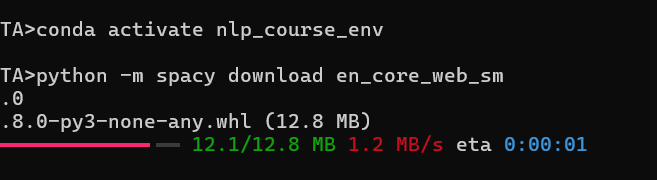

# Open Anaconda Prompt and run:

## conda activate nlp_course_env

## python -m spacy download en_core_web_sm

In [7]:
nlp = spacy.load('en_core_web_sm')
# if you are running this for the first time, or recieve an error "Can't find model 'en_core_web_sm'", 
# then please run the follwing in your terminal: python -m spacy download en_core_web_sm

In [8]:
# our text is from jane austin's 'emma'
# we have removed punctuation, lowercased but left in stop words
emma_ja = "emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twentyone years in the world with very little to distress or vex her she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sisters marriage been mistress of his house from a very early period her mother had died too long ago for her to have more than an indistinct remembrance of her caresses and her place had been supplied by an excellent woman as governess who had fallen little short of a mother in affection sixteen years had miss taylor been in mr woodhouses family less as a governess than a friend very fond of both daughters but particularly of emma between them it was more the intimacy of sisters even before miss taylor had ceased to hold the nominal office of governess the mildness of her temper had hardly allowed her to impose any restraint and the shadow of authority being now long passed away they had been living together as friend and friend very mutually attached and emma doing just what she liked highly esteeming miss taylors judgment but directed chiefly by her own"
print(emma_ja)

emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twentyone years in the world with very little to distress or vex her she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sisters marriage been mistress of his house from a very early period her mother had died too long ago for her to have more than an indistinct remembrance of her caresses and her place had been supplied by an excellent woman as governess who had fallen little short of a mother in affection sixteen years had miss taylor been in mr woodhouses family less as a governess than a friend very fond of both daughters but particularly of emma between them it was more the intimacy of sisters even before miss taylor had ceased to hold the nominal office of governess the mildness of her temper had hardly allowed her to impose any restraint and the shadow of auth

In [9]:
# create a spacy doc from our text - this will generate tokens and their assosciated pos tags
spacy_doc = nlp(emma_ja)

In [10]:
# extract the tokens and pos tags into a dataframe
pos_df = pd.DataFrame(columns=['token', 'pos_tag'])

In [11]:
for token in spacy_doc:
    pos_df = pd.concat([pos_df,
                       pd.DataFrame.from_records([{'token': token.text, 'pos_tag': token.pos_}])], ignore_index=True)

In [12]:
pos_df.head(15)

,token,pos_tag
0,emma,PROPN
1,woodhouse,PROPN
2,handsome,ADJ
3,clever,ADJ
4,and,CCONJ
5,rich,ADJ
6,with,ADP
7,a,DET
8,comfortable,ADJ
9,home,NOUN


In [13]:
# token frequency count
pos_df_counts = pos_df.groupby(['token','pos_tag']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
pos_df_counts.head(10)

,token,pos_tag,counts
88,of,ADP,14
49,had,AUX,9
54,her,PRON,9
111,the,DET,8
6,and,CCONJ,8
0,a,DET,6
114,to,PART,5
61,in,ADP,4
13,been,AUX,4
120,very,ADV,4


In [14]:
# counts of pos_tags
pos_df_poscounts = pos_df_counts.groupby(['pos_tag'])['token'].count().sort_values(ascending=False)
pos_df_poscounts.head(10)

pos_tag
NOUN     35
VERB     19
ADJ      18
ADV      18
PRON      9
ADP       8
PROPN     6
DET       5
AUX       4
CCONJ     3
Name: token, dtype: int64

In [15]:
# see most common nouns
nouns = pos_df_counts[pos_df_counts.pos_tag == "NOUN"][0:10]
nouns

,token,pos_tag,counts
48,governess,NOUN,3
46,friend,NOUN,3
130,years,NOUN,2
35,emma,NOUN,2
28,daughters,NOUN,2
103,sisters,NOUN,2
82,mother,NOUN,2
89,office,NOUN,1
78,mistress,NOUN,1
75,mildness,NOUN,1


In [16]:
# see most common verbs
verbs = pos_df_counts[pos_df_counts.pos_tag == "ADJ"][0:10]
verbs

,token,pos_tag,counts
70,little,ADJ,2
91,own,ADJ,1
86,nominal,ADJ,1
79,more,ADJ,1
102,short,ADJ,1
98,rich,ADJ,1
34,early,ADJ,1
26,comfortable,ADJ,1
25,clever,ADJ,1
16,best,ADJ,1


# Named Entity Recognition

In [1]:
import spacy
from spacy import displacy
from spacy import tokenizer
import re
nlp = spacy.load('en_core_web_sm')

In [2]:
google_text = "Google was founded on September 4, 1998, by computer scientists Larry Page and Sergey Brin while they were PhD students at Stanford University in California. Together they own about 14% of its publicly listed shares and control 56% of its stockholder voting power through super-voting stock. The company went public via an initial public offering (IPO) in 2004. In 2015, Google was reorganized as a wholly owned subsidiary of Alphabet Inc. Google is Alphabet's largest subsidiary and is a holding company for Alphabet's internet properties and interests. Sundar Pichai was appointed CEO of Google on October 24, 2015, replacing Larry Page, who became the CEO of Alphabet. On December 3, 2019, Pichai also became the CEO of Alphabet."
print(google_text)

Google was founded on September 4, 1998, by computer scientists Larry Page and Sergey Brin while they were PhD students at Stanford University in California. Together they own about 14% of its publicly listed shares and control 56% of its stockholder voting power through super-voting stock. The company went public via an initial public offering (IPO) in 2004. In 2015, Google was reorganized as a wholly owned subsidiary of Alphabet Inc. Google is Alphabet's largest subsidiary and is a holding company for Alphabet's internet properties and interests. Sundar Pichai was appointed CEO of Google on October 24, 2015, replacing Larry Page, who became the CEO of Alphabet. On December 3, 2019, Pichai also became the CEO of Alphabet.


In [3]:
spacy_doc = nlp(google_text)


for word in spacy_doc.ents:
    print(word.text,word.label_)

Google ORG
September 4, 1998 DATE
Larry Page PERSON
Sergey Brin PERSON
PhD WORK_OF_ART
Stanford University ORG
California GPE
about 14% PERCENT
56% PERCENT
IPO ORG
2004 DATE
2015 DATE
Google ORG
Alphabet Inc. ORG
Alphabet ORG
Alphabet ORG
Sundar Pichai PERSON
Google ORG
October 24, 2015 DATE
Larry Page PERSON
Alphabet GPE
December 3, 2019 DATE
Pichai PERSON
Alphabet GPE


In [4]:
displacy.render(spacy_doc, style="ent", jupyter=True)

In [5]:
google_text_clean = re.sub(r'[^\w\s]', '', google_text).lower() # remove punctuation and lowercase
print(google_text_clean)

google was founded on september 4 1998 by computer scientists larry page and sergey brin while they were phd students at stanford university in california together they own about 14 of its publicly listed shares and control 56 of its stockholder voting power through supervoting stock the company went public via an initial public offering ipo in 2004 in 2015 google was reorganized as a wholly owned subsidiary of alphabet inc google is alphabets largest subsidiary and is a holding company for alphabets internet properties and interests sundar pichai was appointed ceo of google on october 24 2015 replacing larry page who became the ceo of alphabet on december 3 2019 pichai also became the ceo of alphabet


In [6]:
spacy_doc_clean = nlp(google_text_clean)

In [7]:
for word in spacy_doc_clean.ents:
    print(word.text,word.label_)

google ORG
september 4 1998 DATE
stanford university ORG
california GPE
about 14 CARDINAL
56 CARDINAL
2004 DATE
2015 DATE
alphabet inc google ORG
google ORG
october 24 2015 DATE
larry PERSON
december 3 2019 DATE


In [8]:
displacy.render(spacy_doc_clean,style="ent",jupyter=True)

## This part is practical with BBC_news.csv file

In [9]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import spacy
import re
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
bbc_data = pd.read_csv("bbc_news.csv")

In [11]:
bbc_data.head()

,Unnamed: 0,index,title,pubDate,guid,link,description
0,0,6684,Can I refuse to work?,"Wed, 10 Aug 2022 15:46:18 GMT",https://www.bbc.co.uk/news/business-62147992,https://www.bbc.co.uk/news/business-62147992?a...,With much of the UK enduring another period of...
1,1,9267,'Liz Truss the Brief?' World reacts to UK poli...,"Mon, 17 Oct 2022 11:35:12 GMT",https://www.bbc.co.uk/news/world-63285480,https://www.bbc.co.uk/news/world-63285480?at_m...,The UK's political chaos has been watched arou...
2,2,7387,Rationing energy is nothing new for off-grid c...,"Wed, 31 Aug 2022 05:20:18 GMT",https://www.bbc.co.uk/news/uk-scotland-highlan...,https://www.bbc.co.uk/news/uk-scotland-highlan...,Scoraig in the north west Highlands has long h...
3,3,767,The hunt for superyachts of sanctioned Russian...,"Tue, 22 Mar 2022 14:37:01 GMT",https://www.bbc.co.uk/news/60739336,https://www.bbc.co.uk/news/60739336?at_medium=...,"Wealthy Russians sanctioned by the US, EU and ..."
4,4,3712,Platinum Jubilee: 70 years of the Queen in 70 ...,"Wed, 01 Jun 2022 23:17:33 GMT",https://www.bbc.co.uk/news/uk-61660128,https://www.bbc.co.uk/news/uk-61660128?at_medi...,A quick look back at the Queen's 70 years on t...


In [12]:
bbc_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Unnamed: 0   1000 non-null   int64 
 1   index        1000 non-null   int64 
 2   title        1000 non-null   object
 3   pubDate      1000 non-null   object
 4   guid         1000 non-null   object
 5   link         1000 non-null   object
 6   description  1000 non-null   object
dtypes: int64(2), object(5)
memory usage: 54.8+ KB


In [13]:
titles = pd.DataFrame(bbc_data['title'])
titles.head()

,title
0,Can I refuse to work?
1,'Liz Truss the Brief?' World reacts to UK poli...
2,Rationing energy is nothing new for off-grid c...
3,The hunt for superyachts of sanctioned Russian...
4,Platinum Jubilee: 70 years of the Queen in 70 ...


## Clean data

In [14]:
# lowercase
titles['lowercase'] = titles['title'].str.lower()
titles.head()

,title,lowercase
0,Can I refuse to work?,can i refuse to work?
1,'Liz Truss the Brief?' World reacts to UK poli...,'liz truss the brief?' world reacts to uk poli...
2,Rationing energy is nothing new for off-grid c...,rationing energy is nothing new for off-grid c...
3,The hunt for superyachts of sanctioned Russian...,the hunt for superyachts of sanctioned russian...
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee: 70 years of the queen in 70 ...


In [15]:
# stop word removal
en_stopwords = stopwords.words('english')
titles['no_stopwords'] = titles['lowercase'].apply(lambda x: ' '.join([word for word in x.split() if word not in (en_stopwords)]))
titles.head()

,title,lowercase,no_stopwords
0,Can I refuse to work?,can i refuse to work?,refuse work?
1,'Liz Truss the Brief?' World reacts to UK poli...,'liz truss the brief?' world reacts to uk poli...,'liz truss brief?' world reacts uk political t...
2,Rationing energy is nothing new for off-grid c...,rationing energy is nothing new for off-grid c...,rationing energy nothing new off-grid community
3,The hunt for superyachts of sanctioned Russian...,the hunt for superyachts of sanctioned russian...,hunt superyachts sanctioned russian oligarchs
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee: 70 years of the queen in 70 ...,platinum jubilee: 70 years queen 70 seconds


In [16]:
# punctation removal
titles['no_stopwords_no_punct'] = titles.apply(lambda x: re.sub(r"([^\w\s])", "", x['no_stopwords']), axis=1)
titles.head()

,title,lowercase,no_stopwords,no_stopwords_no_punct
0,Can I refuse to work?,can i refuse to work?,refuse work?,refuse work
1,'Liz Truss the Brief?' World reacts to UK poli...,'liz truss the brief?' world reacts to uk poli...,'liz truss brief?' world reacts uk political t...,liz truss brief world reacts uk political turmoil
2,Rationing energy is nothing new for off-grid c...,rationing energy is nothing new for off-grid c...,rationing energy nothing new off-grid community,rationing energy nothing new offgrid community
3,The hunt for superyachts of sanctioned Russian...,the hunt for superyachts of sanctioned russian...,hunt superyachts sanctioned russian oligarchs,hunt superyachts sanctioned russian oligarchs
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee: 70 years of the queen in 70 ...,platinum jubilee: 70 years queen 70 seconds,platinum jubilee 70 years queen 70 seconds


In [17]:
# tokenize
titles['tokens_raw'] = titles.apply(lambda x: word_tokenize(x['title']), axis=1)
titles['tokens_clean'] = titles.apply(lambda x: word_tokenize(x['no_stopwords_no_punct']), axis=1)
titles.head()

,title,lowercase,no_stopwords,no_stopwords_no_punct,tokens_raw,tokens_clean
0,Can I refuse to work?,can i refuse to work?,refuse work?,refuse work,"[Can, I, refuse, to, work, ?]","[refuse, work]"
1,'Liz Truss the Brief?' World reacts to UK poli...,'liz truss the brief?' world reacts to uk poli...,'liz truss brief?' world reacts uk political t...,liz truss brief world reacts uk political turmoil,"['Liz, Truss, the, Brief, ?, ', World, reacts,...","[liz, truss, brief, world, reacts, uk, politic..."
2,Rationing energy is nothing new for off-grid c...,rationing energy is nothing new for off-grid c...,rationing energy nothing new off-grid community,rationing energy nothing new offgrid community,"[Rationing, energy, is, nothing, new, for, off...","[rationing, energy, nothing, new, offgrid, com..."
3,The hunt for superyachts of sanctioned Russian...,the hunt for superyachts of sanctioned russian...,hunt superyachts sanctioned russian oligarchs,hunt superyachts sanctioned russian oligarchs,"[The, hunt, for, superyachts, of, sanctioned, ...","[hunt, superyachts, sanctioned, russian, oliga..."
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee: 70 years of the queen in 70 ...,platinum jubilee: 70 years queen 70 seconds,platinum jubilee 70 years queen 70 seconds,"[Platinum, Jubilee, :, 70, years, of, the, Que...","[platinum, jubilee, 70, years, queen, 70, seco..."


In [19]:
# lemmatizing 
lemmatizer = WordNetLemmatizer()
titles["tokens_clean_lemmatized"] = titles["tokens_clean"].apply(lambda tokens: [lemmatizer.lemmatize(token) for token in tokens])
titles.head()

,title,lowercase,no_stopwords,no_stopwords_no_punct,tokens_raw,tokens_clean,tokens_clean_lemmatized
0,Can I refuse to work?,can i refuse to work?,refuse work?,refuse work,"[Can, I, refuse, to, work, ?]","[refuse, work]","[refuse, work]"
1,'Liz Truss the Brief?' World reacts to UK poli...,'liz truss the brief?' world reacts to uk poli...,'liz truss brief?' world reacts uk political t...,liz truss brief world reacts uk political turmoil,"['Liz, Truss, the, Brief, ?, ', World, reacts,...","[liz, truss, brief, world, reacts, uk, politic...","[liz, truss, brief, world, reacts, uk, politic..."
2,Rationing energy is nothing new for off-grid c...,rationing energy is nothing new for off-grid c...,rationing energy nothing new off-grid community,rationing energy nothing new offgrid community,"[Rationing, energy, is, nothing, new, for, off...","[rationing, energy, nothing, new, offgrid, com...","[rationing, energy, nothing, new, offgrid, com..."
3,The hunt for superyachts of sanctioned Russian...,the hunt for superyachts of sanctioned russian...,hunt superyachts sanctioned russian oligarchs,hunt superyachts sanctioned russian oligarchs,"[The, hunt, for, superyachts, of, sanctioned, ...","[hunt, superyachts, sanctioned, russian, oliga...","[hunt, superyachts, sanctioned, russian, oliga..."
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee: 70 years of the queen in 70 ...,platinum jubilee: 70 years queen 70 seconds,platinum jubilee 70 years queen 70 seconds,"[Platinum, Jubilee, :, 70, years, of, the, Que...","[platinum, jubilee, 70, years, queen, 70, seco...","[platinum, jubilee, 70, year, queen, 70, second]"


In [20]:
# create lists for just our tokens
tokens_raw_list = sum(titles['tokens_raw'], []) #unpack our lists into a single list
tokens_clean_list = sum(titles['tokens_clean_lemmatized'], [])

## POS Tagging

In [21]:
nlp = spacy.load('en_core_web_sm')

In [22]:
# create a spacy doc from our raw text - better for pos tagging
spacy_doc = nlp(' '.join(tokens_raw_list))

In [23]:
# extract the tokens and pos tags into a dataframe
pos_df = pd.DataFrame(columns=['token', 'pos_tag'])

for token in spacy_doc:
    pos_df = pd.concat([pos_df,
                       pd.DataFrame.from_records([{'token': token.text,'pos_tag': token.pos_}])], ignore_index=True)

In [24]:
# token frequency count
pos_df_counts = pos_df.groupby(['token','pos_tag']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
pos_df_counts.head(10)

,token,pos_tag,counts
95,:,PUNCT,543
8,',PUNCT,300
2897,in,ADP,187
4082,to,PART,175
3268,of,ADP,172
22,-,PUNCT,166
4043,the,DET,163
1856,and,CCONJ,147
15,'s,PART,143
97,?,PUNCT,130


In [25]:
# most common nouns
nouns = pos_df_counts[pos_df_counts.pos_tag == "NOUN"][0:10]
nouns

,token,pos_tag,counts
4267,war,NOUN,35
3552,record,NOUN,15
3416,police,NOUN,14
4356,year,NOUN,14
4316,win,NOUN,14
3061,living,NOUN,13
4009,tax,NOUN,13
2326,day,NOUN,12
3368,people,NOUN,12
2031,boss,NOUN,11


In [26]:
# most common verbs
verbs = pos_df_counts[pos_df_counts.pos_tag == "VERB"][0:10]
verbs

,token,pos_tag,counts
3687,says,VERB,30
9,',VERB,14
2670,found,VERB,13
4317,win,VERB,12
4324,wins,VERB,10
2713,get,VERB,9
2388,dies,VERB,9
3990,take,VERB,8
2982,killed,VERB,8
3686,say,VERB,8


In [27]:
# most common adjectives
adj = pos_df_counts[pos_df_counts.pos_tag == "ADJ"][0:20]
adj

,token,pos_tag,counts
3244,new,ADJ,28
1400,Russian,ADJ,21
2606,final,ADJ,16
19,-,ADJ,14
2625,first,ADJ,12
3199,more,ADJ,10
1994,big,ADJ,9
2835,high,ADJ,9
3000,last,ADJ,8
3304,other,ADJ,8


# NER

In [28]:
# extract the tokens and entity tags into a dataframe
ner_df = pd.DataFrame(columns=['token', 'ner_tag'])

for token in spacy_doc.ents:
    if pd.isna(token.label_) is False:
        ner_df = pd.concat([ner_df, pd.DataFrame.from_records(
            [{'token': token.text, 'ner_tag': token.label_}])], ignore_index=True)

In [29]:
ner_df.head()

,token,ner_tag
0,Liz Truss,PERSON
1,UK,GPE
2,Rationing,PRODUCT
3,superyachts,CARDINAL
4,Russian,NORP


In [30]:
# token frequency count
ner_df_counts = ner_df.groupby(['token','ner_tag']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
ner_df_counts.head(10)

,token,ner_tag,counts
965,Ukraine,GPE,47
955,UK,GPE,36
329,England,GPE,32
819,Russian,NORP,20
957,US,GPE,19
1031,World Cup 2022,EVENT,18
1058,first,ORDINAL,13
918,The Papers,WORK_OF_ART,13
378,France,GPE,12
226,China,GPE,11
